# BPIC-17 — Section 2.4 (Option 2): trace clustering

**Hypothesis.** The BPIC-17 process is a mixture of several simpler behavioural scenarios. If the
applications are split into scenarios by clustering, a process model discovered separately for each
scenario is more precise and simpler than one global model.

Everything is comparable with Section 2.3: same preprocessing (closed cases), same event log with
16 activities for the discovered models (the case features are counted on the A_ and O_ events of the
original log), same train/test split (`splits/`), same discovery setting (Inductive
Miner, noise 0.2, on the variants that cover 90 % of the training cases of the group) and the same
metrics (share of perfectly fitting cases and align-ETC precision from alignments, size = |P| + |T|).

Steps
1. behavioural features per case → 2. K-means on the training cases, k chosen by silhouette →
3. cluster description → 4. stability check → 5. global vs. cluster models →
6. summary and verdict with pre-defined criteria.

## 0. Parameters

All parameters and seeds of the analysis are set here.

In [1]:
from pathlib import Path

SEED = 42                          # random_state of the main K-means, sampling seed
K_RANGE = range(2, 11)              # k = 2 ... 10
KMEANS_N_INIT = 10                 # restarts of K-means per run
SCALER = "StandardScaler"          # features are standardised (fit on train only)
SILHOUETTE_SAMPLE = 10_000         # silhouette on a random sample of training cases (seed SEED)
STABILITY_SEEDS = [1, 2, 3, 4, 5]  # five other random_states for the stability check
STABLE_ARI = 0.80                  # clusters count as stable if every ARI >= this value

NOISE_THRESHOLD = 0.2              # Inductive Miner, same as in Section 2.3 (model v00)
COVERAGE = 0.9                     # discovery log: variants covering 90 % of the cases (as in 2.3)
FINAL_MODEL = Path("models/final/v04/model.pnml")   # final model of Section 2.3 (reference)

IMPROVEMENT = 0.05                 # required gain for the verdict (fitting share and precision)
SMALL_CLUSTER_SHARE = 0.05         # warning: cluster with < 5 % of the training cases
SMALL_CLUSTER_TEST = 200           # warning: cluster with < 200 test cases
OVERFIT_GAP = 0.05                 # warning: |train - test| > 0.05 for a metric of a model

DATA_DIR = Path("BPIC-17 Data")
FIG_DIR = Path("figures/clustering")

## Setup

In [2]:
import os
os.environ["TQDM_DISABLE"] = "1"  # no progress bars (must be set before tqdm is imported)
import shutil
import warnings
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py
import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from src.prep import (CASE, ACT, TS, OUTCOME_ACTIVITIES, load_event_log, drop_open_cases,
                      build_abstraction, filter_top_variants)
from src.abstraction_w import build_log
from src.simplicity import size

warnings.filterwarnings("ignore")
np.random.seed(SEED)

GRAPHVIZ_FALLBACK = Path("/opt/anaconda3/envs/graphviz/bin")
if shutil.which("dot") is None and (GRAPHVIZ_FALLBACK / "dot").exists():
    os.environ["PATH"] = f"{GRAPHVIZ_FALLBACK}{os.pathsep}{os.environ['PATH']}"
assert shutil.which("dot"), "Graphviz not found"

FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
print("pm4py", pm4py.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.12 | scikit-learn 1.9.1 | pandas 3.1.1


## 1. Data and behavioural features

In [3]:
df, n_open = drop_open_cases(load_event_log(DATA_DIR / "BPI Challenge 2017.xes",
                                            DATA_DIR / "bpic17_eventlog.pkl"))
train_ids = set(Path("splits/train_cases.txt").read_text().split("\n"))
test_ids = set(Path("splits/test_cases.txt").read_text().split("\n"))

# features (clustering): A_ and O_ events of the original log, unchanged from the first version of this analysis
feat_log = build_abstraction(df, "L2_AO")[[CASE, ACT, TS]]
feat_train, feat_test = feat_log[feat_log[CASE].isin(train_ids)], feat_log[feat_log[CASE].isin(test_ids)]

# process models: the log level of Section 2.3 (W_ + O_ + A_, 16 activities, src/abstraction_w.py)
log = build_log(df)[0][[CASE, ACT, TS]]
train_log, test_log = log[log[CASE].isin(train_ids)], log[log[CASE].isin(test_ids)]
print(f"closed cases: {log[CASE].nunique()} (removed open: {n_open}) | "
      f"train {train_log[CASE].nunique()} | test {test_log[CASE].nunique()} | "
      f"model log: {log[ACT].nunique()} activities")

closed cases: 31411 (removed open: 98) | train 21988 | test 9423 | model log: 16 activities


Features describe how a case **moves through the process**. The outcome (A_Pending / A_Denied /
A_Cancelled and the O_ events that close the offers) is **not** a feature; it is kept separately
to describe the clusters.

In [4]:
FEATURES = ["n_offers", "n_incomplete", "n_validating", "submitted", "returned", "duration_days"]

def case_features(log):
    g = log.groupby(CASE)
    act = log.assign(one=1).pivot_table(index=CASE, columns=ACT, values="one", aggfunc="sum", fill_value=0)
    get = lambda a: act[a] if a in act else 0
    f = pd.DataFrame(index=act.index)
    f["n_offers"] = get("O_Create Offer")
    f["n_incomplete"] = get("A_Incomplete")
    f["n_validating"] = get("A_Validating")
    f["submitted"] = (get("A_Submitted") > 0).astype(int)
    f["returned"] = (get("O_Returned") > 0).astype(int)
    f["duration_days"] = (g[TS].max() - g[TS].min()).dt.total_seconds() / 86400
    return f[FEATURES].astype(float)

def case_outcome(log):
    out = log[log[ACT].isin(OUTCOME_ACTIVITIES)].groupby(CASE)[ACT].first()
    return out.str.replace("A_", "", regex=False)

X_train, X_test = case_features(feat_train), case_features(feat_test)
outcome = pd.concat([case_outcome(feat_train), case_outcome(feat_test)])
X_train.describe().round(2)

,n_offers,n_incomplete,n_validating,submitted,returned,duration_days
count,21988.00,21988.00,21988.00,21988.00,21988.00,21988.00
mean,1.37,0.73,1.23,0.65,0.69,21.81
std,0.72,0.95,1.12,0.48,0.46,12.88
min,1.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,0.00,11.24
50%,1.00,0.00,1.00,1.00,1.00,19.06
75%,2.00,1.00,2.00,1.00,1.00,31.48
max,10.00,7.00,8.00,1.00,1.00,169.07


## 2. K-means and the number of clusters

The scaler and K-means are fitted on the training cases only. k is chosen by the highest silhouette score (never by the quality of the process models).

In [5]:
scaler = StandardScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)

rng = np.random.default_rng(SEED)
sample = rng.choice(len(Z_train), size=min(SILHOUETTE_SAMPLE, len(Z_train)), replace=False)

kmeans_by_k, sil = {}, {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=SEED).fit(Z_train)
    kmeans_by_k[k] = km
    sil[k] = silhouette_score(Z_train[sample], km.labels_[sample])
sil = pd.Series(sil, name="silhouette score")
BEST_K = int(sil.idxmax())
print(f"chosen k = {BEST_K} (silhouette {sil[BEST_K]:.3f})")
sil.round(3).to_frame()

chosen k = 8 (silhouette 0.429)


,silhouette score
2,0.374
3,0.353
4,0.373
5,0.387
6,0.417
7,0.423
8,0.429
9,0.428
10,0.424


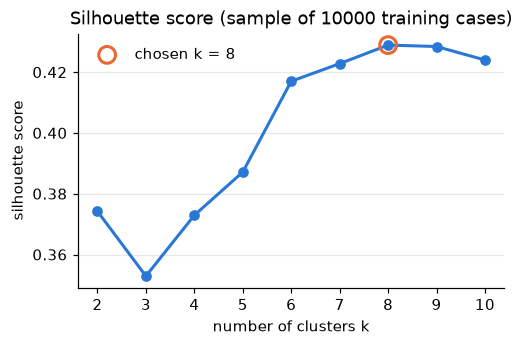

In [6]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(sil.index, sil.values, marker="o", color="#2a78d6", lw=2)
ax.scatter([BEST_K], [sil[BEST_K]], s=120, facecolors="none", edgecolors="#eb6834", lw=2, zorder=3,
           label=f"chosen k = {BEST_K}")
ax.set_xlabel("number of clusters k")
ax.set_ylabel("silhouette score")
ax.set_title(f"Silhouette score (sample of {len(sample)} training cases)")
ax.set_xticks(list(K_RANGE))
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
fig.savefig(FIG_DIR / "silhouette.pdf")
plt.show()

In [7]:
kmeans = kmeans_by_k[BEST_K]
cluster = pd.concat([pd.Series(kmeans.labels_, index=X_train.index),
                     pd.Series(kmeans.predict(Z_test), index=X_test.index)]).rename("cluster")
CLUSTERS = sorted(cluster.unique())
train_cluster, test_cluster = cluster.loc[X_train.index], cluster.loc[X_test.index]

## 3. Cluster description

Means of the features, shares of the outcomes and the median duration are computed on the training cases of each cluster.

In [8]:
rows = []
for c in CLUSTERS:
    ids = train_cluster.index[train_cluster == c]
    f = X_train.loc[ids]
    o = outcome.loc[ids].value_counts(normalize=True)
    rows.append({"cluster": c,
                 "train cases": len(ids), "train share": len(ids) / len(train_cluster),
                 "test cases": int((test_cluster == c).sum()),
                 "test share": (test_cluster == c).mean(),
                 **{f"mean {x}": f[x].mean() for x in FEATURES},
                 "Pending share": o.get("Pending", 0.0), "Denied share": o.get("Denied", 0.0),
                 "Cancelled share": o.get("Cancelled", 0.0),
                 "median duration_days": f["duration_days"].median()})
profile = pd.DataFrame(rows).set_index("cluster")
profile.round(3)

,train cases,train share,test cases,test share,mean n_offers,mean n_incomplete,mean n_validating,mean submitted,mean returned,mean duration_days,Pending share,Denied share,Cancelled share,median duration_days
cluster,,,,,,,,,,,,,,
0,4187,0.190,1816,0.193,1.175,0.543,1.380,0.000,0.999,13.632,0.839,0.132,0.029,12.067
1,822,0.037,361,0.038,1.794,1.627,2.055,0.804,0.985,50.904,0.663,0.099,0.238,46.883
2,6076,0.276,2647,0.281,1.201,0.559,1.353,1.000,1.000,15.376,0.712,0.257,0.031,13.731
3,4916,0.224,2041,0.217,1.261,0.001,0.004,1.000,0.000,29.717,0.000,0.022,0.978,31.855
4,924,0.042,393,0.042,3.723,1.039,1.650,0.658,0.878,25.195,0.718,0.123,0.159,22.813
5,1320,0.060,538,0.057,1.398,2.425,2.984,0.000,0.999,19.922,0.900,0.061,0.039,17.979
6,1770,0.080,772,0.082,1.215,0.014,0.018,0.000,0.000,27.512,0.000,0.021,0.979,30.750
7,1973,0.090,855,0.091,1.386,2.431,2.943,1.000,0.998,21.666,0.883,0.067,0.050,20.456


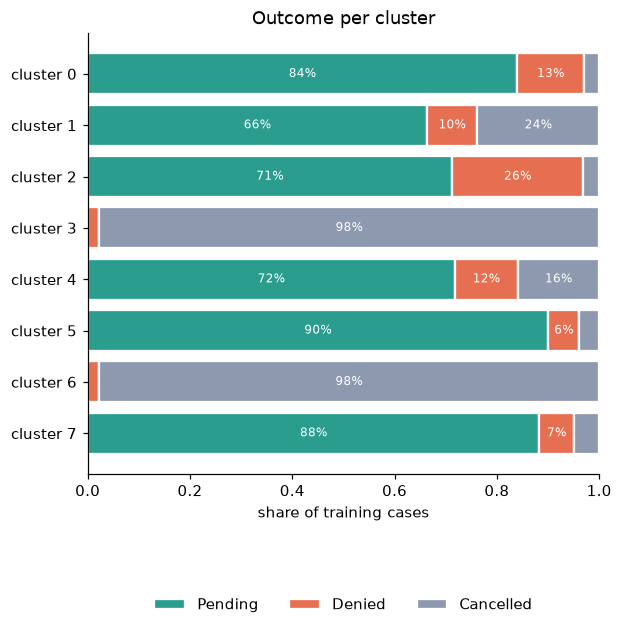

In [9]:
OUTCOME_COLORS = {"Pending": "#2a9d8f", "Denied": "#e76f51", "Cancelled": "#8d99ae"}
shares = profile[[f"{o} share" for o in OUTCOME_COLORS]]
shares.columns = list(OUTCOME_COLORS)

fig, ax = plt.subplots(figsize=(6, 0.5 * len(CLUSTERS) + 1.2))
left = np.zeros(len(shares))
for o, color in OUTCOME_COLORS.items():
    ax.barh([f"cluster {c}" for c in shares.index], shares[o], left=left, color=color, label=o,
            edgecolor="white", linewidth=1.5)
    for i, v in enumerate(shares[o]):
        if v >= 0.06:
            ax.text(left[i] + v / 2, i, f"{100 * v:.0f}%", ha="center", va="center", fontsize=8, color="white")
    left += shares[o].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of training cases")
ax.set_title("Outcome per cluster")
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.show()

## 4. Stability of the clusters

K-means is repeated with five other `random_state` values; the partitions are compared with the Adjusted Rand Index (1 = identical, ~0 = random agreement).

In [10]:
labelings = {f"seed {SEED} (main)": kmeans.labels_}
for s in STABILITY_SEEDS:
    labelings[f"seed {s}"] = KMeans(n_clusters=BEST_K, n_init=KMEANS_N_INIT, random_state=s).fit(Z_train).labels_
names = list(labelings)
ari = pd.DataFrame(np.eye(len(names)), index=names, columns=names)
for a, b in combinations(names, 2):
    ari.loc[a, b] = ari.loc[b, a] = adjusted_rand_score(labelings[a], labelings[b])
pairs = [ari.loc[a, b] for a, b in combinations(names, 2)]
STABLE = min(pairs) >= STABLE_ARI
print(f"ARI over all pairs: mean {np.mean(pairs):.3f}, min {min(pairs):.3f} -> "
      f"{'STABLE' if STABLE else 'NOT STABLE'} (threshold {STABLE_ARI})")
ari.round(3)

ARI over all pairs: mean 0.822, min 0.677 -> NOT STABLE (threshold 0.8)


,seed 42 (main),seed 1,seed 2,seed 3,seed 4,seed 5
seed 42 (main),1.000,0.677,0.996,0.788,0.764,0.762
seed 1,0.677,1.000,0.677,0.815,0.818,0.819
seed 2,0.996,0.677,1.000,0.787,0.762,0.759
seed 3,0.788,0.815,0.787,1.000,0.957,0.952
seed 4,0.764,0.818,0.762,0.957,1.000,0.995
seed 5,0.762,0.819,0.759,0.952,0.995,1.000


## 5. Process models: global vs. per cluster

* **Global model**: Inductive Miner (noise 0.2) on the discovery log of all training cases
  (variants covering 90 % of the cases) — the same setting as model v00 in Section 2.3.
* **Cluster models**: the same discovery on the training cases of each cluster.
* Metrics as in Section 2.3, from alignments: **fitting share** (share of perfectly fitting cases),
  **precision** (align-ETC), **size** = |P| + |T| of the Petri net. Each model is evaluated on its
  test cases and, to check overfitting, on its training cases.
* The global model is additionally evaluated on the test cases of every cluster, so that a cluster
  model can be compared with the global model on exactly the same cases.
* The final model of Section 2.3 is evaluated in the same way as a **reference** only.

The models are discovered and evaluated on the event log of Section 2.3 (W_ + O_ + A_, 16 activities); the clustering features are unchanged.

In [11]:
def discover(part_log, name):
    """Inductive Miner on the discovery log of `part_log`."""
    disc, n_var = filter_top_variants(part_log, COVERAGE)
    tree = pm4py.discover_process_tree_inductive(disc, noise_threshold=NOISE_THRESHOLD)
    net, im, fm = pm4py.convert_to_petri_net(tree)
    return {"net": (net, im, fm), "bpmn": pm4py.convert_to_bpmn(tree), "variants kept": n_var,
            "discovery cases": disc[CASE].nunique(), "sound": pm4py.check_soundness(net, im, fm)[0]}

def evaluate(net, im, fm, part_log):
    """Fitting share and align-ETC precision, as in Section 2.3."""
    fit = pm4py.fitness_alignments(part_log, net, im, fm, multi_processing=False)
    prec = pm4py.precision_alignments(part_log, net, im, fm, multi_processing=False)
    return {"fitting share": fit["percFitTraces"] / 100, "precision": prec}

def cases_of(part_log, ids):
    return part_log[part_log[CASE].isin(set(ids))]

In [12]:
models = {"global": discover(train_log, "global")}
for c in CLUSTERS:
    models[f"cluster {c}"] = discover(cases_of(train_log, train_cluster.index[train_cluster == c]), f"cluster_{c}")
final_net = pm4py.read_pnml(str(FINAL_MODEL))
pd.DataFrame({m: {k: v for k, v in d.items() if k not in ("net", "bpmn")} for m, d in models.items()}).T

,variants kept,discovery cases,sound
global,403,19790,True
cluster 0,16,3770,True
cluster 1,302,740,True
cluster 2,43,5474,True
cluster 3,9,4441,True
cluster 4,585,832,True
cluster 5,190,1188,True
cluster 6,5,1607,True
cluster 7,284,1776,True


In [13]:
rows = []

def add_row(model, evaluated_on, net_im_fm, train_part, test_part, kind):
    te = evaluate(*net_im_fm, test_part)
    tr = evaluate(*net_im_fm, train_part) if train_part is not None else {"fitting share": np.nan, "precision": np.nan}
    rows.append({"model": model, "kind": kind, "evaluated on (test)": evaluated_on,
                 "test cases": test_part[CASE].nunique(),
                 "test fitting share": te["fitting share"], "test precision": te["precision"],
                 "train fitting share": tr["fitting share"], "train precision": tr["precision"],
                 "size": size(net_im_fm[0])})

add_row("global", "all test cases", models["global"]["net"], train_log, test_log, "global")
for c in CLUSTERS:
    tr_part = cases_of(train_log, train_cluster.index[train_cluster == c])
    te_part = cases_of(test_log, test_cluster.index[test_cluster == c])
    add_row(f"cluster {c}", f"test cases of cluster {c}", models[f"cluster {c}"]["net"], tr_part, te_part, "cluster")
    add_row("global", f"test cases of cluster {c}", models["global"]["net"], None, te_part, "global on cluster")
add_row("final model v04 (reference)", "all test cases", final_net, train_log, test_log, "reference")
results = pd.DataFrame(rows)
results.round(3)

,model,kind,evaluated on (test),test cases,test fitting share,test precision,train fitting share,train precision,size
0,global,global,all test cases,9423,0.649,0.713,0.643,0.730,65
1,cluster 0,cluster,test cases of cluster 0,1816,0.863,0.703,0.853,0.720,44
2,global,global on cluster,test cases of cluster 0,1816,0.739,0.599,NaN,NaN,65
3,cluster 1,cluster,test cases of cluster 1,361,0.493,0.536,0.509,0.540,78
4,global,global on cluster,test cases of cluster 1,361,0.357,0.580,NaN,NaN,65
5,cluster 2,cluster,test cases of cluster 2,2647,0.698,0.710,0.710,0.745,51
6,global,global on cluster,test cases of cluster 2,2647,0.587,0.629,NaN,NaN,65
7,cluster 3,cluster,test cases of cluster 3,2041,0.779,0.922,0.780,0.924,30
8,global,global on cluster,test cases of cluster 3,2041,0.773,0.660,NaN,NaN,65
9,cluster 4,cluster,test cases of cluster 4,393,0.514,0.373,0.473,0.397,80


## 6. Summary and verdict

In [14]:
glob = results[(results.kind == "global")].iloc[0]
clus = results[results.kind == "cluster"].copy()
clus["cluster"] = CLUSTERS
clus["weight"] = clus["test cases"] / clus["test cases"].sum()
glob_on = results[results.kind == "global on cluster"]   # same order as the clusters
clus["global fitting (same cases)"] = glob_on["test fitting share"].values
clus["global precision (same cases)"] = glob_on["test precision"].values
clus["Δ fitting vs global"] = clus["test fitting share"] - clus["global fitting (same cases)"]
clus["Δ precision vs global"] = clus["test precision"] - clus["global precision (same cases)"]
clus["smaller than global"] = clus["size"] < glob["size"]
clus["improved (≥ 0.05 both, smaller)"] = ((clus["Δ fitting vs global"] >= IMPROVEMENT)
                                          & (clus["Δ precision vs global"] >= IMPROVEMENT)
                                          & clus["smaller than global"])

w_fit = (clus["weight"] * clus["test fitting share"]).sum()
w_prec = (clus["weight"] * clus["test precision"]).sum()
ref = results[results.kind == "reference"].iloc[0]
summary = pd.DataFrame([
    {"model": "global", "test fitting share": glob["test fitting share"], "test precision": glob["test precision"],
     "size": glob["size"]},
    *[{"model": f"cluster {r.cluster}", "test fitting share": r["test fitting share"],
       "test precision": r["test precision"], "size": r["size"]} for _, r in clus.iterrows()],
    {"model": "clusters, weighted mean", "test fitting share": w_fit, "test precision": w_prec,
     "size": np.nan},
    {"model": "clusters, total size", "test fitting share": np.nan, "test precision": np.nan,
     "size": clus["size"].sum()},
    {"model": "final model v04 (reference)", "test fitting share": ref["test fitting share"],
     "test precision": ref["test precision"], "size": ref["size"]},
]).set_index("model")
display(summary.round(3))
clus[["cluster", "weight", "test fitting share", "global fitting (same cases)", "Δ fitting vs global",
      "test precision", "global precision (same cases)", "Δ precision vs global", "size",
      "smaller than global", "improved (≥ 0.05 both, smaller)"]].round(3)

,test fitting share,test precision,size
model,,,
global,0.649,0.713,65.0
cluster 0,0.863,0.703,44.0
cluster 1,0.493,0.536,78.0
cluster 2,0.698,0.710,51.0
cluster 3,0.779,0.922,30.0
cluster 4,0.514,0.373,80.0
cluster 5,0.662,0.522,59.0
cluster 6,0.828,0.895,23.0
cluster 7,0.599,0.571,61.0


,cluster,weight,test fitting share,global fitting (same cases),Δ fitting vs global,test precision,global precision (same cases),Δ precision vs global,size,smaller than global,"improved (≥ 0.05 both, smaller)"
1,0,0.193,0.863,0.739,0.124,0.703,0.599,0.104,44,True,True
3,1,0.038,0.493,0.357,0.136,0.536,0.580,-0.044,78,False,False
5,2,0.281,0.698,0.587,0.111,0.710,0.629,0.082,51,True,True
7,3,0.217,0.779,0.773,0.006,0.922,0.660,0.262,30,True,False
9,4,0.042,0.514,0.061,0.453,0.373,0.681,-0.308,80,False,False
11,5,0.057,0.662,0.660,0.002,0.522,0.478,0.043,59,True,False
13,6,0.082,0.828,0.811,0.017,0.895,0.611,0.284,23,True,False
15,7,0.091,0.599,0.596,0.002,0.571,0.530,0.041,61,True,False


**Verdict criteria (fixed before running the analysis).** Let Δ be the weighted mean of the cluster
models minus the global model on all test cases.

* **CONFIRMED**: Δ fitting share ≥ 0.05 **and** Δ precision ≥ 0.05 **and** every cluster model is
  smaller than the global model.
* **PARTIALLY CONFIRMED**: not confirmed, but at least one cluster model is better than the global
  model **on the test cases of the same cluster** by ≥ 0.05 in both fitting share and precision and
  is smaller than the global model.
* **REJECTED**: otherwise (weighted metrics not better by ≥ 0.05 or cluster models not simpler, and no
  single cluster satisfies the condition above).

In [15]:
d_fit, d_prec = w_fit - glob["test fitting share"], w_prec - glob["test precision"]
all_smaller = bool(clus["smaller than global"].all())
improved = clus.loc[clus["improved (≥ 0.05 both, smaller)"], "cluster"].tolist()

if d_fit >= IMPROVEMENT and d_prec >= IMPROVEMENT and all_smaller:
    verdict = "CONFIRMED"
elif improved:
    verdict = "PARTIALLY CONFIRMED"
else:
    verdict = "REJECTED"

print(f"weighted fitting share {w_fit:.3f} vs global {glob['test fitting share']:.3f} (Δ {d_fit:+.3f})")
print(f"weighted precision     {w_prec:.3f} vs global {glob['test precision']:.3f} (Δ {d_prec:+.3f})")
print(f"every cluster model smaller than global ({glob['size']}): {all_smaller} "
      f"(sizes {clus['size'].tolist()}, total {clus['size'].sum()})")
print(f"clusters improved on their own test cases: {improved if improved else 'none'}")
print(f"\nVERDICT: {verdict}")

weighted fitting share 0.731 vs global 0.649 (Δ +0.082)
weighted precision     0.726 vs global 0.713 (Δ +0.013)
every cluster model smaller than global (65): False (sizes [44, 78, 51, 30, 80, 59, 23, 61], total 426)
clusters improved on their own test cases: [0, 2]

VERDICT: PARTIALLY CONFIRMED


In [16]:
warn = []
for _, r in clus.iterrows():
    share = profile.loc[r.cluster, "train share"]
    if share < SMALL_CLUSTER_SHARE or r["test cases"] < SMALL_CLUSTER_TEST:
        warn.append(f"small cluster {r.cluster}: {100 * share:.1f}% of training cases, "
                    f"{r['test cases']} test cases")
for _, r in results[results["train fitting share"].notna()].iterrows():
    for m in ["fitting share", "precision"]:
        gap = r[f"train {m}"] - r[f"test {m}"]
        if abs(gap) > OVERFIT_GAP:
            warn.append(f"possible overfitting, {r.model}: train {m} {r[f'train {m}']:.3f} "
                        f"vs test {r[f'test {m}']:.3f} (gap {gap:+.3f})")
if not STABLE:
    warn.append(f"clusters are not stable: minimum ARI {min(pairs):.3f} < {STABLE_ARI}")
if BEST_K == max(K_RANGE):
    warn.append(f"chosen k = {BEST_K} is the upper end of the tested range")
if not all(d["sound"] for d in models.values()):
    warn.append("not every discovered model is sound")
print("WARNINGS" if warn else "No warnings.")
for w in warn:
    print(" -", w)

WARNINGS
 - small cluster 1: 3.7% of training cases, 361 test cases
 - small cluster 4: 4.2% of training cases, 393 test cases
 - possible overfitting, cluster 5: train precision 0.610 vs test 0.522 (gap +0.088)
 - clusters are not stable: minimum ARI 0.677 < 0.8


## 7. Comparison figure and model pictures

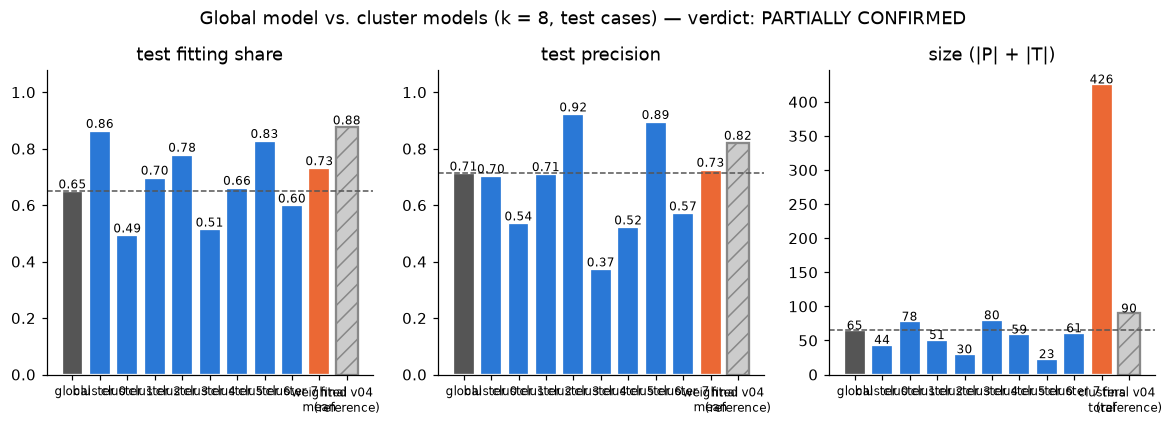

In [17]:
labels = ["global"] + [f"cluster {c}" for c in CLUSTERS] + ["weighted\nmean", "final v04\n(reference)"]
colors = ["#555555"] + ["#2a78d6"] * len(CLUSTERS) + ["#eb6834", "#cccccc"]

def style_reference(bars):
    """The last bar (final model v04) is a hatched reference."""
    bars[-1].set_hatch("//")
    bars[-1].set_edgecolor("#888888")
values = {
    "test fitting share": [glob["test fitting share"], *clus["test fitting share"], w_fit, ref["test fitting share"]],
    "test precision": [glob["test precision"], *clus["test precision"], w_prec, ref["test precision"]],
}
size_labels = ["global"] + [f"cluster {c}" for c in CLUSTERS] + ["clusters\ntotal", "final v04\n(reference)"]
size_vals = [glob["size"], *clus["size"], clus["size"].sum(), ref["size"]]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (metric, vals) in zip(axes[:2], values.items()):
    bars = ax.bar(labels, vals, color=colors, edgecolor="white", linewidth=1.5)
    style_reference(bars)
    ax.axhline(vals[0], color="#555555", lw=1, ls="--")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
    ax.set_ylim(0, 1.08)
    ax.set_title(metric)
    ax.tick_params(axis="x", labelsize=8)
bars = axes[2].bar(size_labels, size_vals, color=colors, edgecolor="white", linewidth=1.5)
style_reference(bars)
axes[2].axhline(glob["size"], color="#555555", lw=1, ls="--")
for b, v in zip(bars, size_vals):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}", ha="center", fontsize=8)
axes[2].set_title("size (|P| + |T|)")
axes[2].tick_params(axis="x", labelsize=8)
fig.suptitle(f"Global model vs. cluster models (k = {BEST_K}, test cases) — verdict: {verdict}", y=1.03)
plt.show()

global


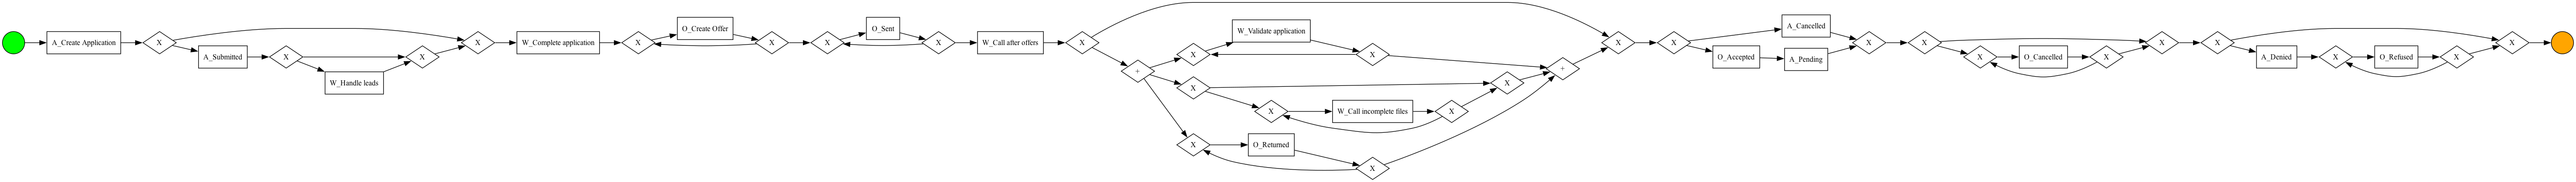

cluster 0


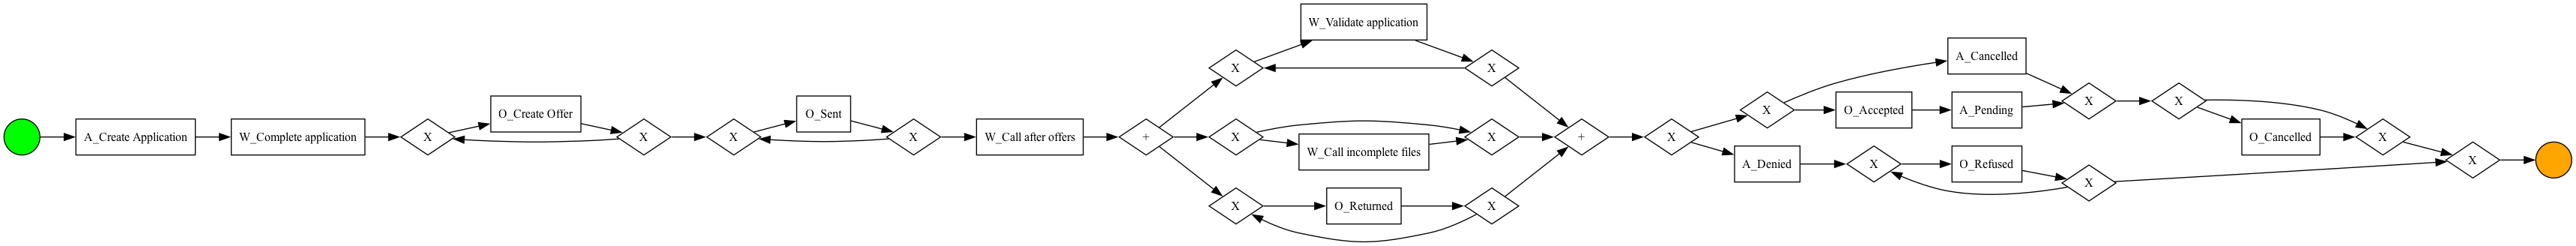

cluster 1


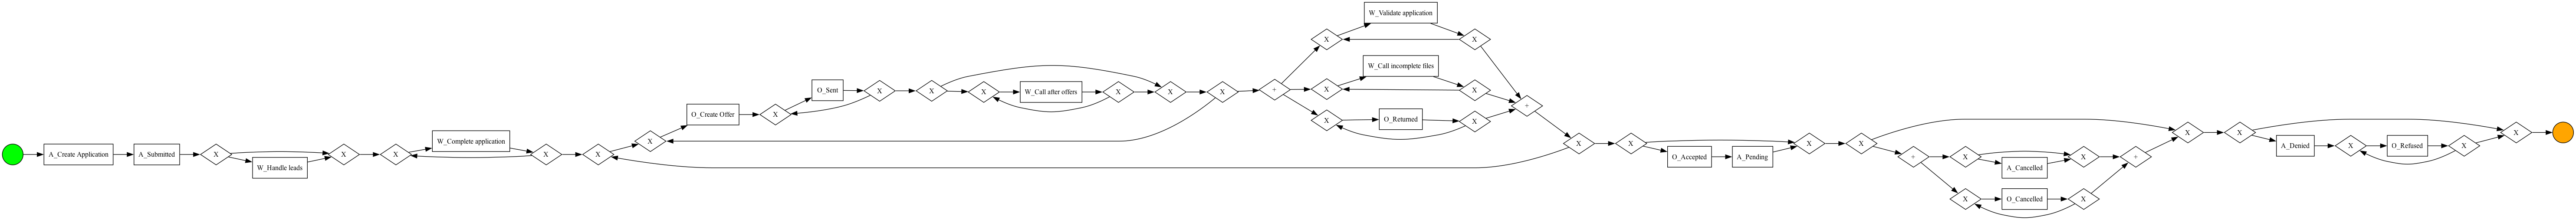

cluster 2


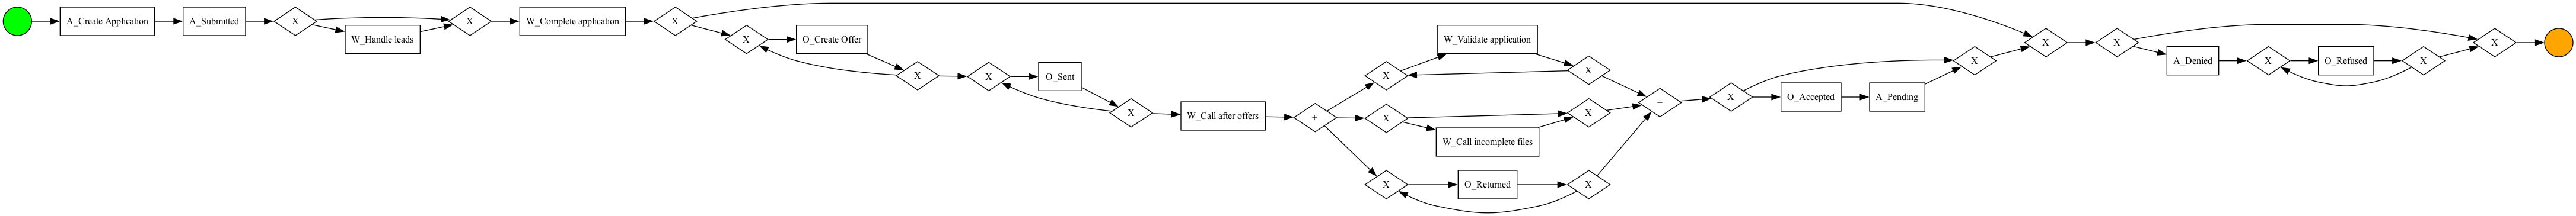

cluster 3


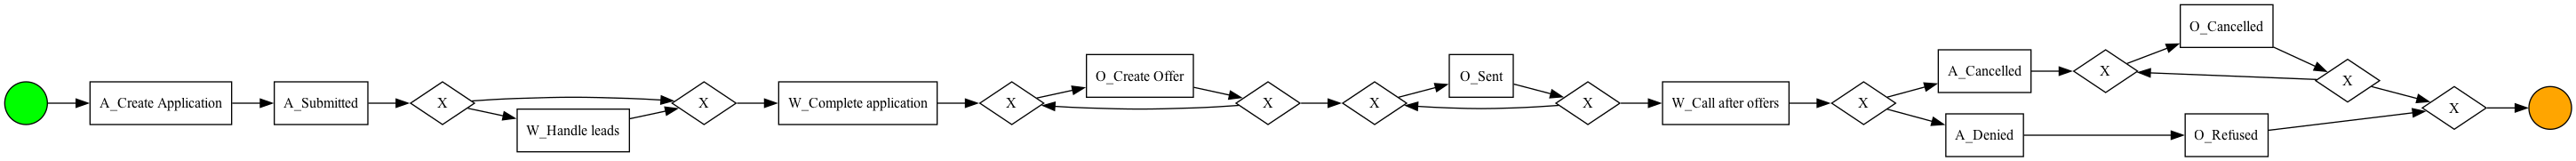

cluster 4


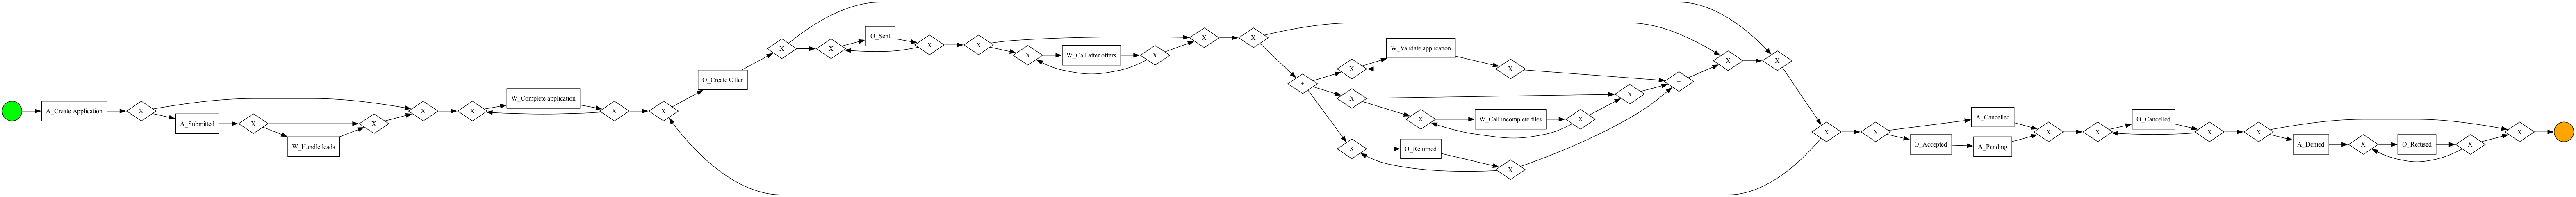

cluster 5


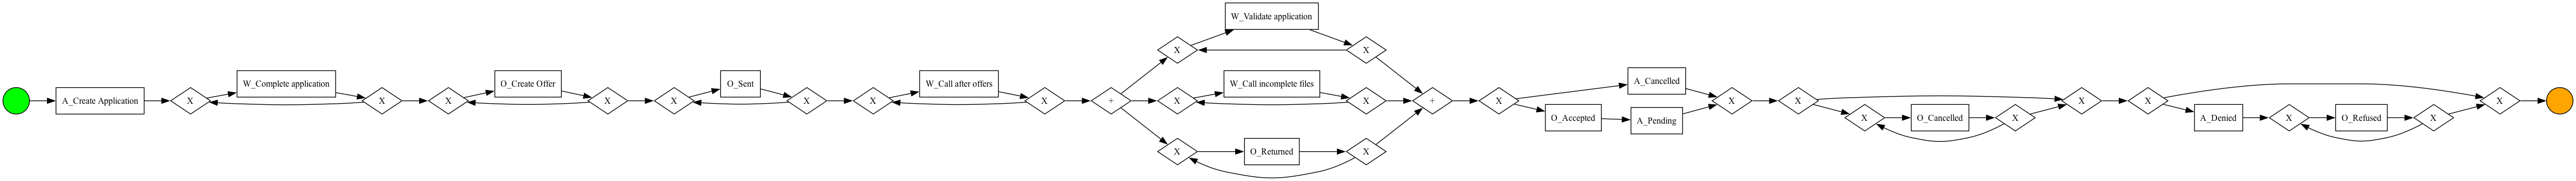

cluster 6


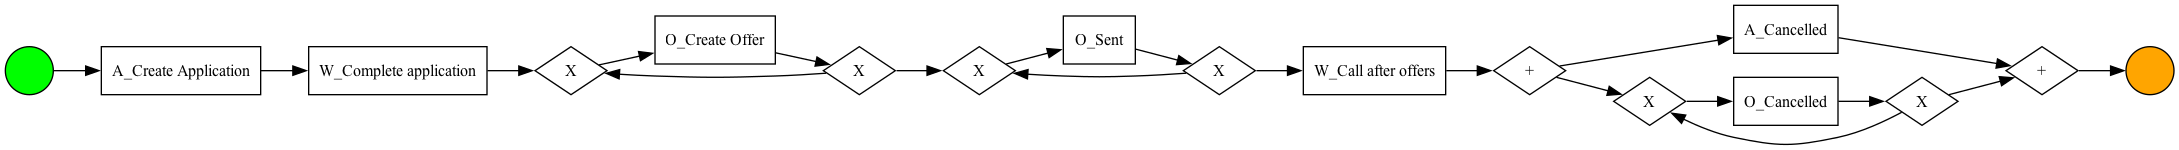

cluster 7


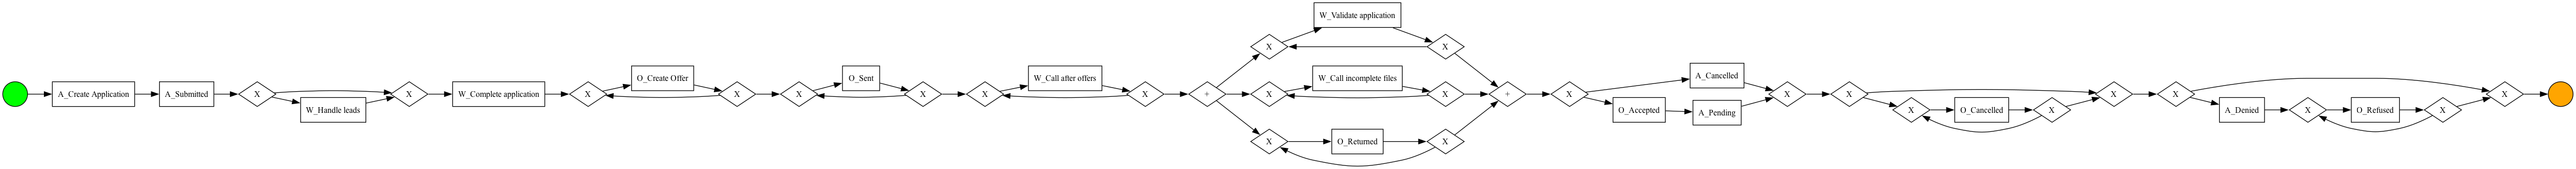

In [18]:
# pictures of the discovered models (for viewing only, not saved)
for name, d in models.items():
    print(name)
    pm4py.view_bpmn(d["bpmn"], rankdir="LR")

## Output

* `figures/clustering/silhouette.pdf` — silhouette score for k = 2 … 8
* the comparison of the global model, the cluster models, their weighted mean and the final model
  is drawn for the report by `src/report_assets.py` from the stored outputs of this notebook